In [ ]:
import numpy as np  # numeric arrays
import pandas as pd  # tables (DataFrame)
import matplotlib.pyplot as plt  # plotting
from sklearn.preprocessing import StandardScaler  # feature scaling
from sklearn.cluster import KMeans  # the K-Means algorithm
from sklearn.metrics import silhouette_score  # cluster-quality score


In [2]:
import numpy as np  # numeric arrays
import pandas as pd  # tables (DataFrame)

np.random.seed(42)  # repeatable random numbers
centers = [(4, 20), (4, 80), (12, 50), (21, 18), (21, 82)]
    # (income in lakh, score) of 5 hidden groups
groups = []  # list to collect each group's customers
for inc, sc in centers:  # for each hidden group
    g = np.column_stack([np.random.normal(inc, 1.3, 40), np.random.normal(sc, 8, 40)])
        # 40 customers scattered around its centre
    groups.append(g)  # store the group
df = pd.DataFrame(np.vstack(groups), columns=['AnnualIncome_Lakh', 'SpendingScore'])
    # stack all 200 customers into a table
df['SpendingScore'] = df['SpendingScore'].clip(1, 100)  # keep score within 1-100
df['AnnualIncome_Lakh'] = df['AnnualIncome_Lakh'].clip(lower=1)  # income cannot be below 1 lakh
df.insert(0, 'CustomerID', range(1, 201))  # add an ID column
print('Shape:', df.shape)  # (rows, columns)
df.round(1).head()  # first 5 customers

Shape: (200, 3)


,CustomerID,AnnualIncome_Lakh,SpendingScore
0,1,4.6,25.9
1,2,3.8,21.4
2,3,4.8,19.1
3,4,6.0,17.6
4,5,3.7,8.2


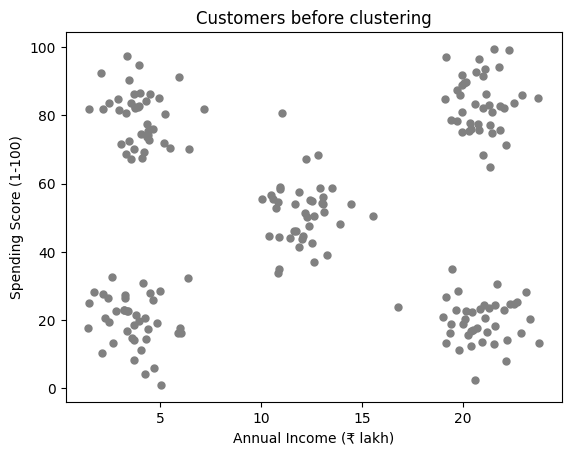

In [4]:
import matplotlib.pyplot as plt  # plotting

plt.scatter(df['AnnualIncome_Lakh'], df['SpendingScore'], color='grey', s=25)
    # all points in one colour - no labels exist
plt.xlabel('Annual Income (₹ lakh)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customers before clustering')
plt.show()

In [6]:
from sklearn.preprocessing import StandardScaler  # feature scaling

X = df[['AnnualIncome_Lakh', 'SpendingScore']]  # the two features used for clustering
scaler = StandardScaler()  # create the scaler
X_scaled = scaler.fit_transform(X)  # scale to mean 0, std 1
print('Mean:', X_scaled.mean(axis=0).round(2))  # should be about 0
print('Std :', X_scaled.std(axis=0).round(2))  # should be 1

Mean: [0. 0.]
Std : [1. 1.]


K=2: inertia=233.6, silhouette=0.419
K=3: inertia=136.6, silhouette=0.529
K=4: inertia=60.1, silhouette=0.646
K=5: inertia=19.2, silhouette=0.737
K=6: inertia=17.0, silhouette=0.682
K=7: inertia=14.9, silhouette=0.621
K=8: inertia=12.9, silhouette=0.564
K=9: inertia=11.6, silhouette=0.484
K=10: inertia=9.8, silhouette=0.423


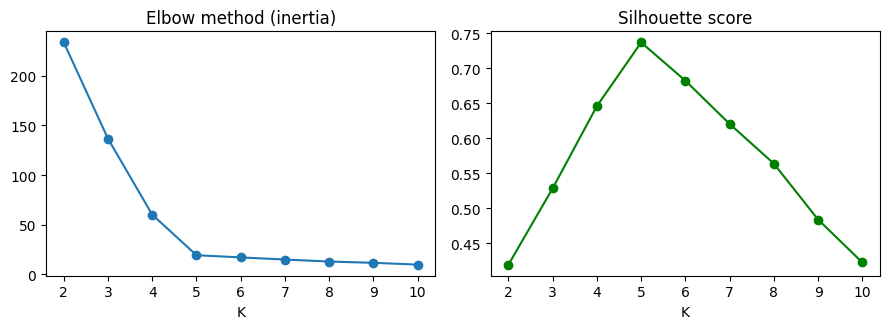

In [8]:
from sklearn.cluster import KMeans  # the K-Means algorithm
from sklearn.metrics import silhouette_score  # cluster-quality score
import matplotlib.pyplot as plt  # plotting

inertias, sil_scores = [], []  # lists to store both measures
k_range = range(2, 11)  # try K = 2 to 10
for k in k_range:  # repeat for every K
    km = KMeans(n_clusters=k, n_init=10, random_state=42)  # K-Means with this K
    labels = km.fit_predict(X_scaled)  # fit and get each point's cluster
    inertias.append(km.inertia_)  # store inertia (for the elbow)
    sil_scores.append(silhouette_score(X_scaled, labels))  # store silhouette score
    print(f'K={k}: inertia={km.inertia_:.1f}, silhouette={sil_scores[-1]:.3f}')  # show both
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))  # two plots side by side
ax[0].plot(k_range, inertias, marker='o')  # elbow curve
ax[0].set_title('Elbow method (inertia)')
ax[0].set_xlabel('K')
ax[1].plot(k_range, sil_scores, marker='o', color='green')  # silhouette curve
ax[1].set_title('Silhouette score')
ax[1].set_xlabel('K')
plt.tight_layout()  # avoid overlapping labels
plt.show()

In [9]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)  # K-Means with the chosen K = 5
df['Cluster'] = kmeans.fit_predict(X_scaled)  # cluster number for every customer
print(df['Cluster'].value_counts().sort_index())  # customers per cluster
print(df.groupby('Cluster')[['AnnualIncome_Lakh', 'SpendingScore']].mean().round(1))
    # average profile of each cluster


Cluster
0    41
1    40
2    40
3    40
4    39
Name: count, dtype: int64
         AnnualIncome_Lakh  SpendingScore
Cluster                                  
0                      4.2           79.8
1                     20.9           19.8
2                      3.7           19.8
3                     20.9           83.7
4                     12.1           50.8


In [10]:
kmeans = KMeans(n_clusters=5, n_init=10, random_state=42)  # K-Means with the chosen K = 5
df['Cluster'] = kmeans.fit_predict(X_scaled)  # cluster number for every customer
print(df['Cluster'].value_counts().sort_index())  # customers per cluster
print(df.groupby('Cluster')[['AnnualIncome_Lakh', 'SpendingScore']].mean().round(1))
    # average profile of each cluster


Cluster
0    41
1    40
2    40
3    40
4    39
Name: count, dtype: int64
         AnnualIncome_Lakh  SpendingScore
Cluster                                  
0                      4.2           79.8
1                     20.9           19.8
2                      3.7           19.8
3                     20.9           83.7
4                     12.1           50.8


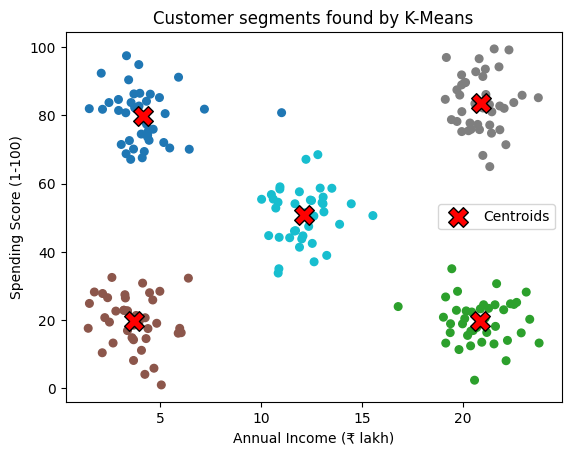

In [11]:
plt.scatter(df['AnnualIncome_Lakh'], df['SpendingScore'], c=df['Cluster'], cmap='tab10', s=30)
    # colour = cluster
cent = scaler.inverse_transform(kmeans.cluster_centers_)  # convert centroids back to original units
plt.scatter(cent[:, 0], cent[:, 1], c='red', marker='X', s=200, edgecolors='black', label='Centroids')
    # mark centroids
plt.xlabel('Annual Income (₹ lakh)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer segments found by K-Means')
plt.legend()
plt.show()


In [12]:
new_customer = pd.DataFrame([[20.0, 85.0]], columns=X.columns)  # income 20 lakh, spending score 85
cluster = kmeans.predict(scaler.transform(new_customer))[0]  # nearest centroid (after scaling)
print('Assigned to cluster:', cluster)
print('Cluster average profile:', df[df['Cluster'] == cluster][['AnnualIncome_Lakh', 'SpendingScore']].mean().round(1).to_dict())
    # its typical customer


Assigned to cluster: 3
Cluster average profile: {'AnnualIncome_Lakh': 20.9, 'SpendingScore': 83.7}
